# Etapa 4 - Modelagem

- Essa etapa consiste em carregar as bases construídas na etapa de feature engineering, implementar os modelos de previsão e escolher a melhor configuração de cada um. Os modelos avaliados são:
  1. **Seasonal Naive**: modelo de referência (baseline), que repete as vendas da última semana.
  2. **ARIMA**: modelo estatístico clássico, sem componente sazonal.
  3. **SARIMA**: ARIMA com componente sazonal semanal.
  4. **SARIMAX**: SARIMA com as variáveis de eventos como variáveis exógenas.
  5. **XGBoost**: modelo de machine learning baseado em árvores de decisão (gradient boosting).
  6. **LightGBM**: outro modelo de gradient boosting, com uma forma diferente de construir as árvores.
- Todos os modelos são avaliados com o mesmo esquema de validação e as mesmas métricas, o que permite compará-los de forma justa. A base de teste (23/07/2018 a 19/08/2018) não é utilizada nesta etapa: ela fica reservada para a avaliação final na etapa 5.

In [1]:
# Importando as bibliotecas
import pandas as pd
import seaborn as sns
# Configurando o matplotlib
%matplotlib inline                              
import matplotlib.pyplot as plt
import numpy as np
import itertools
import json
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
import xgboost as xgb
import lightgbm as lgb

import warnings

# Ignorando os warnings dos modelos estatísticos durante as buscas de parâmetros (o número máximo de iterações foi aumentado para 200 para garantir a convergência)
warnings.filterwarnings("ignore")

In [2]:
# Carregando as bases de dados
df_ts = pd.read_csv(r'../data/sales_db_03_ts.csv', index_col = 'sale_date', parse_dates = True).asfreq('D')
df_ml = pd.read_csv(r'../data/sales_db_03_ml.csv', index_col = 'sale_date', parse_dates = True).asfreq('D')

In [3]:
# Visualizando as informações das bases
df_ts.info()
print()
df_ml.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 592 entries, 2017-01-05 to 2018-08-19
Freq: D
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   order_units          592 non-null    int64  
 1   log_units            592 non-null    float64
 2   feriado              592 non-null    int64  
 3   black_friday         592 non-null    int64  
 4   pos_black_friday     592 non-null    int64  
 5   fim_de_ano           592 non-null    int64  
 6   greve_caminhoneiros  592 non-null    int64  
 7   split                592 non-null    object 
dtypes: float64(1), int64(6), object(1)
memory usage: 41.6+ KB

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 537 entries, 2017-03-01 to 2018-08-19
Freq: D
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   month                  537 non-null    int64  
 1   day_of_week 

In [4]:
# Definindo as listas de variáveis
eventos = ['feriado', 'black_friday', 'pos_black_friday', 'fim_de_ano', 'greve_caminhoneiros']
features = [col for col in df_ml.columns if col not in ['split', 'order_units']]

# Separando o histórico disponível para a modelagem (sem a base de teste)
df_hist = df_ts.loc[df_ts['split'] != 'teste']

### Estratégia de validação

- Em séries temporais, a validação cruzada tradicional (KFold com embaralhamento) não é adequada, porque o modelo seria treinado com dados posteriores aos que está prevendo. A abordagem correta é simular previsões reais: treinar o modelo com os dados até uma data e prever o período seguinte.
- Avaliar os modelos em uma única janela de 4 semanas é arriscado, já que um período atípico pode favorecer um modelo por acaso. A própria janela de validação definida na etapa 3 (25/06/2018 a 22/07/2018) coincide com a Copa do Mundo de 2018 (14/06/2018 a 15/07/2018).
- Por isso, foi adotada a **validação com origem móvel** (backtest): os modelos são avaliados em 4 janelas consecutivas de 28 dias, sendo a última delas a janela de validação. Em cada janela, o modelo é treinado com todo o histórico anterior ao início da janela e prevê os 28 dias seguintes. O resultado final de cada modelo é a média das 4 janelas.

In [5]:
# Definindo o início das 4 janelas de validação (cada janela tem 28 dias, a última termina em 22/07/2018)
horizonte = 28
inicio_janelas = pd.date_range(end = '2018-06-25', periods = 4, freq = '28D')

# Avaliando o período e a média de vendas de cada janela
janelas = pd.DataFrame({'inicio' : inicio_janelas, 'fim' : inicio_janelas + pd.Timedelta(days = horizonte - 1)})
janelas['media_vendas'] = [df_hist.loc[ini:fim, 'order_units'].mean().round(1) for ini, fim in zip(janelas['inicio'], janelas['fim'])]
janelas.index = ['Janela 1', 'Janela 2', 'Janela 3', 'Janela 4']
janelas

,inicio,fim,media_vendas
Janela 1,2018-04-02,2018-04-29,258.9
Janela 2,2018-04-30,2018-05-27,264.6
Janela 3,2018-05-28,2018-06-24,221.8
Janela 4,2018-06-25,2018-07-22,207.9


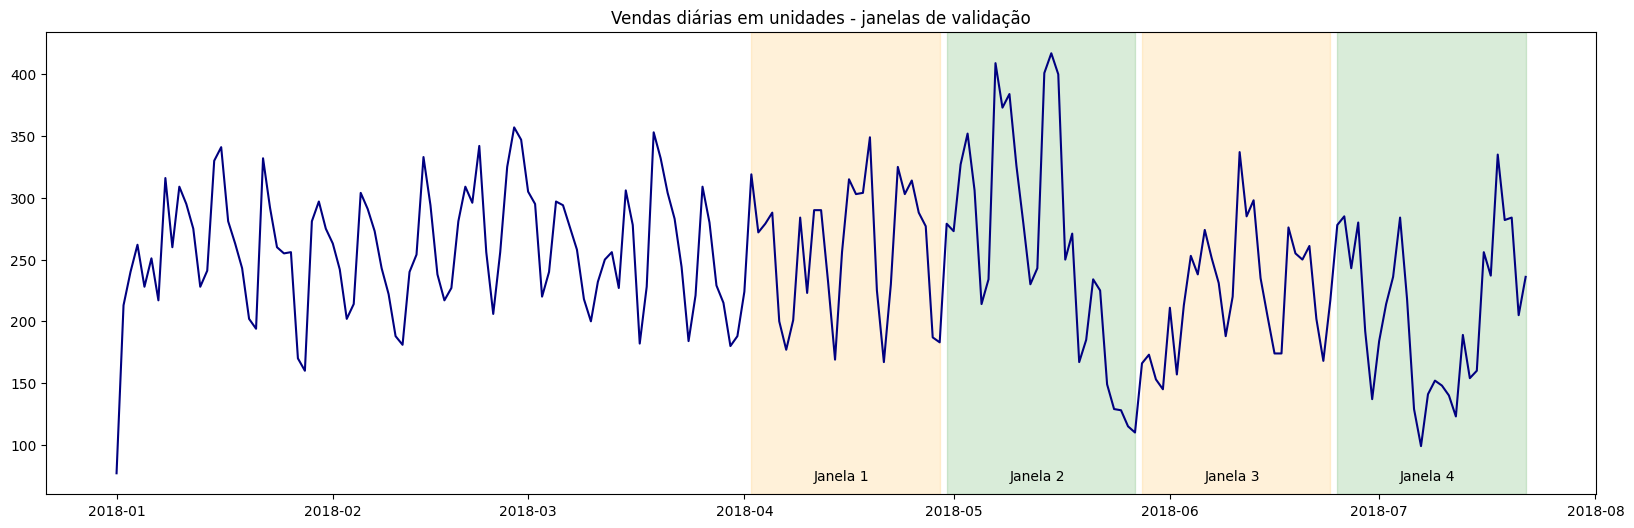

In [6]:
# Plotando as janelas de validação
fig, ax = plt.subplots(figsize = (20,6))

ax.plot(df_hist.loc['2018-01-01':, 'order_units'], color = 'navy')
for i, (ini, fim) in enumerate(zip(janelas['inicio'], janelas['fim'])):
    ax.axvspan(ini, fim, alpha = 0.15, color = ['orange', 'green'][i % 2])
    ax.text(ini + pd.Timedelta(days = 9), 0.03, 'Janela {}'.format(i + 1), transform = ax.get_xaxis_transform())    # Texto posicionado na parte inferior do gráfico
plt.title('Vendas diárias em unidades - janelas de validação')

plt.show()

### Métricas de avaliação

- As métricas são calculadas sobre o total de unidades vendidas por dia:
  - **MAE** (erro absoluto médio): erro médio por dia, em unidades.
  - **RMSE** (raiz do erro quadrático médio): também em unidades, mas penaliza mais os erros grandes.
  - **WMAPE** (erro percentual absoluto médio ponderado): soma dos erros absolutos dividida pela soma das vendas reais. É a **métrica principal** do projeto, por ser em percentual (fácil de interpretar pela área de negócio). O WMAPE é uma variação do MAPE: no MAPE, o erro percentual de cada dia tem o mesmo peso, então dias com vendas baixas (como os sábados ou os dias de feriado) geram erros percentuais altos e distorcem a média. No WMAPE, cada dia pesa de acordo com o seu volume de vendas.
  - **Erro no total do período**: diferença percentual entre o total previsto e o total real das 4 semanas. Indica se o modelo superestima (positivo) ou subestima (negativo) as vendas no horizonte usado para o planejamento.

In [7]:
# Definindo função para cálculo das métricas
def calcular_metricas(real, previsto):
    erro = real - previsto
    return {'MAE' : np.abs(erro).mean(),
            'RMSE' : np.sqrt((erro ** 2).mean()),
            'WMAPE (%)' : 100 * np.abs(erro).sum() / real.sum(),
            'Erro total (%)' : 100 * (previsto.sum() / real.sum() - 1)}

In [8]:
# Definindo função para o backtest: treina e prevê cada janela e calcula as métricas
def backtest(funcao_previsao):
    resultados = []
    previsoes = []
    for inicio in inicio_janelas:
        treino = df_hist.loc[:inicio - pd.Timedelta(days = 1)]                       # Todo o histórico anterior à janela
        futuro = df_hist.loc[inicio:inicio + pd.Timedelta(days = horizonte - 1)]     # 28 dias a serem previstos
        previsto = np.asarray(funcao_previsao(treino, futuro))
        resultados.append(calcular_metricas(futuro['order_units'].values, previsto))
        previsoes.append(pd.Series(previsto, index = futuro.index))
    resultados = pd.DataFrame(resultados, index = ['Janela 1', 'Janela 2', 'Janela 3', 'Janela 4'])
    resultados.loc['Média'] = resultados.mean()
    return resultados.round(2), pd.concat(previsoes)

- A greve dos caminhoneiros foi um evento inesperado: diferente dos feriados ou da Black Friday, não era possível saber com antecedência que ela aconteceria. Assim, no período previsto, a variável `greve_caminhoneiros` é sempre preenchida com zero, mesmo na janela 2, que contém os dias da greve. A variável continua sendo utilizada no treino, para que os modelos entendam que aquela queda foi uma exceção.

In [9]:
# Definindo função para montar as variáveis de eventos do período previsto
def eventos_futuro(futuro):
    exog = futuro[eventos].copy()
    exog['greve_caminhoneiros'] = 0         # Evento não conhecido com antecedência
    return exog

In [10]:
# Dicionários para armazenar os resultados e as previsões de cada modelo
resultados_modelos = {}
previsoes_modelos = {}

### Modelo 1 - Seasonal Naive (baseline)

- O Seasonal Naive é o modelo mais simples possível para uma série com sazonalidade semanal: a previsão de cada dia é igual às vendas do mesmo dia da semana na última semana conhecida.
- Ele serve como referência: um modelo mais complexo só se justifica se tiver um erro menor que o Seasonal Naive.

In [11]:
# Definindo a função de previsão do Seasonal Naive
def prever_seasonal_naive(treino, futuro):
    ultima_semana = treino['order_units'].iloc[-7:].values
    return np.tile(ultima_semana, horizonte // 7)

# Executando o backtest
resultados_modelos['Seasonal Naive'], previsoes_modelos['Seasonal Naive'] = backtest(prever_seasonal_naive)
resultados_modelos['Seasonal Naive']

,MAE,RMSE,WMAPE (%),Erro total (%)
Janela 1,41.50,52.59,16.03,-10.34
Janela 2,62.71,76.26,23.70,1.32
Janela 3,74.61,83.87,33.64,-29.78
Janela 4,48.32,61.23,23.24,11.94
Média,56.79,68.49,24.15,-6.72


- O Seasonal Naive teve um WMAPE médio de 24,2%, valor que passa a ser a referência para os demais modelos.
- O pior resultado foi na janela 3 (33,6%): a última semana conhecida antes dessa janela foi a semana da greve dos caminhoneiros, e o modelo repetiu as vendas baixas da greve durante as 4 semanas seguintes. Essa é a principal fraqueza do modelo: qualquer semana atípica é replicada integralmente na previsão.

### Modelo 2 - ARIMA

- O ARIMA(p, d, q) combina três componentes: autorregressivo (p, quantos valores passados são utilizados), diferenciação (d, quantas vezes a série é diferenciada para ficar estacionária) e médias móveis (q, quantos erros passados são utilizados).
- Conforme a EDA, uma diferenciação é suficiente para tornar a série estacionária, então foi fixado **d = 1**. Os modelos são ajustados na série em logaritmo (`log_units`) e as previsões são convertidas de volta para unidades com a função exponencial.
- As ordens p e q são escolhidas pelo **critério de informação de Akaike (AIC)**, que equilibra a qualidade do ajuste e o número de parâmetros (quanto menor, melhor). Para não usar informações das janelas de validação na escolha, a busca é feita com os dados anteriores à primeira janela (até 01/04/2018).

In [12]:
# Separando os dados para a seleção das ordens (anteriores à primeira janela de validação)
dados_selecao = df_hist.loc[:inicio_janelas[0] - pd.Timedelta(days = 1), 'log_units']

# Buscando as ordens p e q com o menor AIC
busca_arima = []
for p, q in itertools.product([0, 1, 2], [0, 1, 2]):
    modelo = SARIMAX(dados_selecao, order = (p, 1, q)).fit(disp = False, maxiter = 200)
    busca_arima.append({'order' : (p, 1, q), 'AIC' : modelo.aic})

busca_arima = pd.DataFrame(busca_arima).sort_values('AIC')
busca_arima.head(5)

,order,AIC
8,"(2, 1, 2)",85.467367
7,"(2, 1, 1)",99.541160
5,"(1, 1, 2)",102.011075
2,"(0, 1, 2)",102.282411
4,"(1, 1, 1)",108.142254


In [13]:
# Definindo a melhor ordem
ordem_arima = busca_arima.iloc[0]['order']

# Definindo a função de previsão do ARIMA
def prever_arima(treino, futuro):
    modelo = SARIMAX(treino['log_units'], order = ordem_arima).fit(disp = False, maxiter = 200)
    return np.exp(modelo.forecast(horizonte))

# Executando o backtest
resultados_modelos['ARIMA'], previsoes_modelos['ARIMA'] = backtest(prever_arima)
resultados_modelos['ARIMA']

,MAE,RMSE,WMAPE (%),Erro total (%)
Janela 1,59.43,69.27,22.95,-17.94
Janela 2,79.23,98.56,29.94,-13.79
Janela 3,107.14,117.54,48.32,-48.32
Janela 4,51.74,62.16,24.89,10.46
Média,74.38,86.89,31.52,-17.39


- A busca pelo AIC indicou o ARIMA(2,1,2).
- O ARIMA teve um WMAPE médio de 31,5%, pior que o Seasonal Naive em todas as janelas. Sem o componente sazonal, o modelo não reproduz o padrão semanal de vendas, que é a principal característica da série. Assim como o baseline, ele também sofre na janela 3 (48,3%), já que parte do nível baixo de vendas da greve.
- Esse resultado confirma a conclusão da EDA de que é necessário modelar a sazonalidade semanal.

### Modelo 3 - SARIMA

- O SARIMA(p, d, q)(P, D, Q)s adiciona ao ARIMA os componentes sazonais: P, D e Q têm o mesmo significado de p, d e q, mas aplicados nos lags sazonais (7, 14, 21... dias), com período **s = 7**.
- Conforme a EDA, foram fixadas uma diferenciação simples e uma sazonal (**d = 1 e D = 1**). A análise da ACF e da PACF indicou o SARIMA(0,1,1)(0,1,1)7 como ponto de partida, e a busca pelo AIC avalia as combinações próximas a ele.

In [14]:
# Buscando as ordens com o menor AIC
busca_sarima = []
for p, q, P, Q in itertools.product([0, 1, 2], [0, 1, 2], [0, 1], [0, 1]):
    modelo = SARIMAX(dados_selecao, order = (p, 1, q), seasonal_order = (P, 1, Q, 7)).fit(disp = False, maxiter = 200)
    busca_sarima.append({'order' : (p, 1, q), 'seasonal_order' : (P, 1, Q, 7), 'AIC' : modelo.aic})

busca_sarima = pd.DataFrame(busca_sarima).sort_values('AIC')
busca_sarima.head(5)

,order,seasonal_order,AIC
17,"(1, 1, 1)","(0, 1, 1, 7)",-10.721736
9,"(0, 1, 2)","(0, 1, 1, 7)",-10.198217
19,"(1, 1, 1)","(1, 1, 1, 7)",-9.549387
33,"(2, 1, 2)","(0, 1, 1, 7)",-9.040642
11,"(0, 1, 2)","(1, 1, 1, 7)",-8.944842


In [15]:
# Definindo as melhores ordens
ordem_sarima = busca_sarima.iloc[0]['order']
ordem_sazonal = busca_sarima.iloc[0]['seasonal_order']

# Definindo a função de previsão do SARIMA
def prever_sarima(treino, futuro):
    modelo = SARIMAX(treino['log_units'], order = ordem_sarima, seasonal_order = ordem_sazonal).fit(disp = False, maxiter = 200)
    return np.exp(modelo.forecast(horizonte))

# Executando o backtest
resultados_modelos['SARIMA'], previsoes_modelos['SARIMA'] = backtest(prever_sarima)
resultados_modelos['SARIMA']

,MAE,RMSE,WMAPE (%),Erro total (%)
Janela 1,25.70,30.86,9.92,-2.10
Janela 2,69.71,81.76,26.34,-4.74
Janela 3,85.33,94.88,38.48,-38.26
Janela 4,54.47,68.06,26.20,19.66
Média,58.80,68.89,25.24,-6.36


- A busca pelo AIC indicou o SARIMA(1,1,1)(0,1,1)7, muito próximo do ponto de partida sugerido pela ACF e pela PACF na EDA, com a adição de um termo autorregressivo.
- O SARIMA obteve o melhor resultado até aqui na janela 1 (WMAPE de 9,9%), mostrando que o componente sazonal captura bem o padrão semanal. Porém, na janela 3 o erro chegou a 38,5%: assim como os modelos anteriores, o SARIMA interpretou a queda da greve como um novo nível de vendas. Com isso, o WMAPE médio (25,2%) ficou um pouco acima do Seasonal Naive.

### Modelo 4 - SARIMAX (SARIMA + eventos)

- O SARIMAX utiliza as mesmas ordens do SARIMA e acrescenta as variáveis de eventos como variáveis exógenas. Assim, o modelo estima o efeito de cada evento separadamente, e esses dias deixam de distorcer a tendência e a sazonalidade.

In [16]:
# Definindo a função de previsão do SARIMAX
def prever_sarimax(treino, futuro):
    modelo = SARIMAX(treino['log_units'], exog = treino[eventos], order = ordem_sarima, seasonal_order = ordem_sazonal).fit(disp = False, maxiter = 200)
    return np.exp(modelo.forecast(horizonte, exog = eventos_futuro(futuro)))

# Executando o backtest
resultados_modelos['SARIMAX'], previsoes_modelos['SARIMAX'] = backtest(prever_sarimax)
resultados_modelos['SARIMAX']

,MAE,RMSE,WMAPE (%),Erro total (%)
Janela 1,20.97,27.43,8.10,1.72
Janela 2,72.17,84.40,27.27,-2.08
Janela 3,28.96,41.06,13.06,5.23
Janela 4,54.20,69.17,26.07,20.67
Média,44.07,55.52,18.63,6.38


- O SARIMAX teve um WMAPE médio de 18,6%, o melhor resultado até aqui, com 23% de melhoria em relação ao baseline.
- A principal diferença está na janela 3, em que o erro caiu de 38,5% (SARIMA) para 13,0%. Com a variável `greve_caminhoneiros`, o modelo entende que a queda daqueles dias foi uma exceção e não a projeta para as semanas seguintes. Na janela 1 o erro também caiu, para 8,1%.
- As janelas 2 e 4 continuam com erros em torno de 26% a 27%. Na janela 2, há um pico de vendas em meados de maio (dias acima de 400 unidades) e os últimos dias da greve, que não eram conhecidos com antecedência. Na janela 4, as vendas caem bastante no início de julho, durante as semanas finais da Copa do Mundo. São eventos que não estão representados nos dados e, portanto, não podem ser antecipados pelo modelo.

- Na EDA, a transformação logarítmica foi indicada para estabilizar a variação da série. Para confirmar essa decisão, o SARIMAX é avaliado também com a série original em unidades.

In [17]:
# Definindo a função de previsão do SARIMAX com a série original (sem logaritmo)
def prever_sarimax_original(treino, futuro):
    modelo = SARIMAX(treino['order_units'], exog = treino[eventos], order = ordem_sarima, seasonal_order = ordem_sazonal).fit(disp = False, maxiter = 200)
    return modelo.forecast(horizonte, exog = eventos_futuro(futuro))

# Executando o backtest e comparando as duas versões
resultado_original, _ = backtest(prever_sarimax_original)
pd.DataFrame({'SARIMAX (log)' : resultados_modelos['SARIMAX'].loc['Média'], 'SARIMAX (original)' : resultado_original.loc['Média']})

,SARIMAX (log),SARIMAX (original)
MAE,44.07,45.30
RMSE,55.52,56.90
WMAPE (%),18.63,19.12
Erro total (%),6.38,4.59


- A versão em logaritmo teve um WMAPE um pouco menor (18,6% contra 19,1%). Assim, a transformação logarítmica é mantida, com a vantagem adicional de garantir que as previsões sejam sempre positivas.

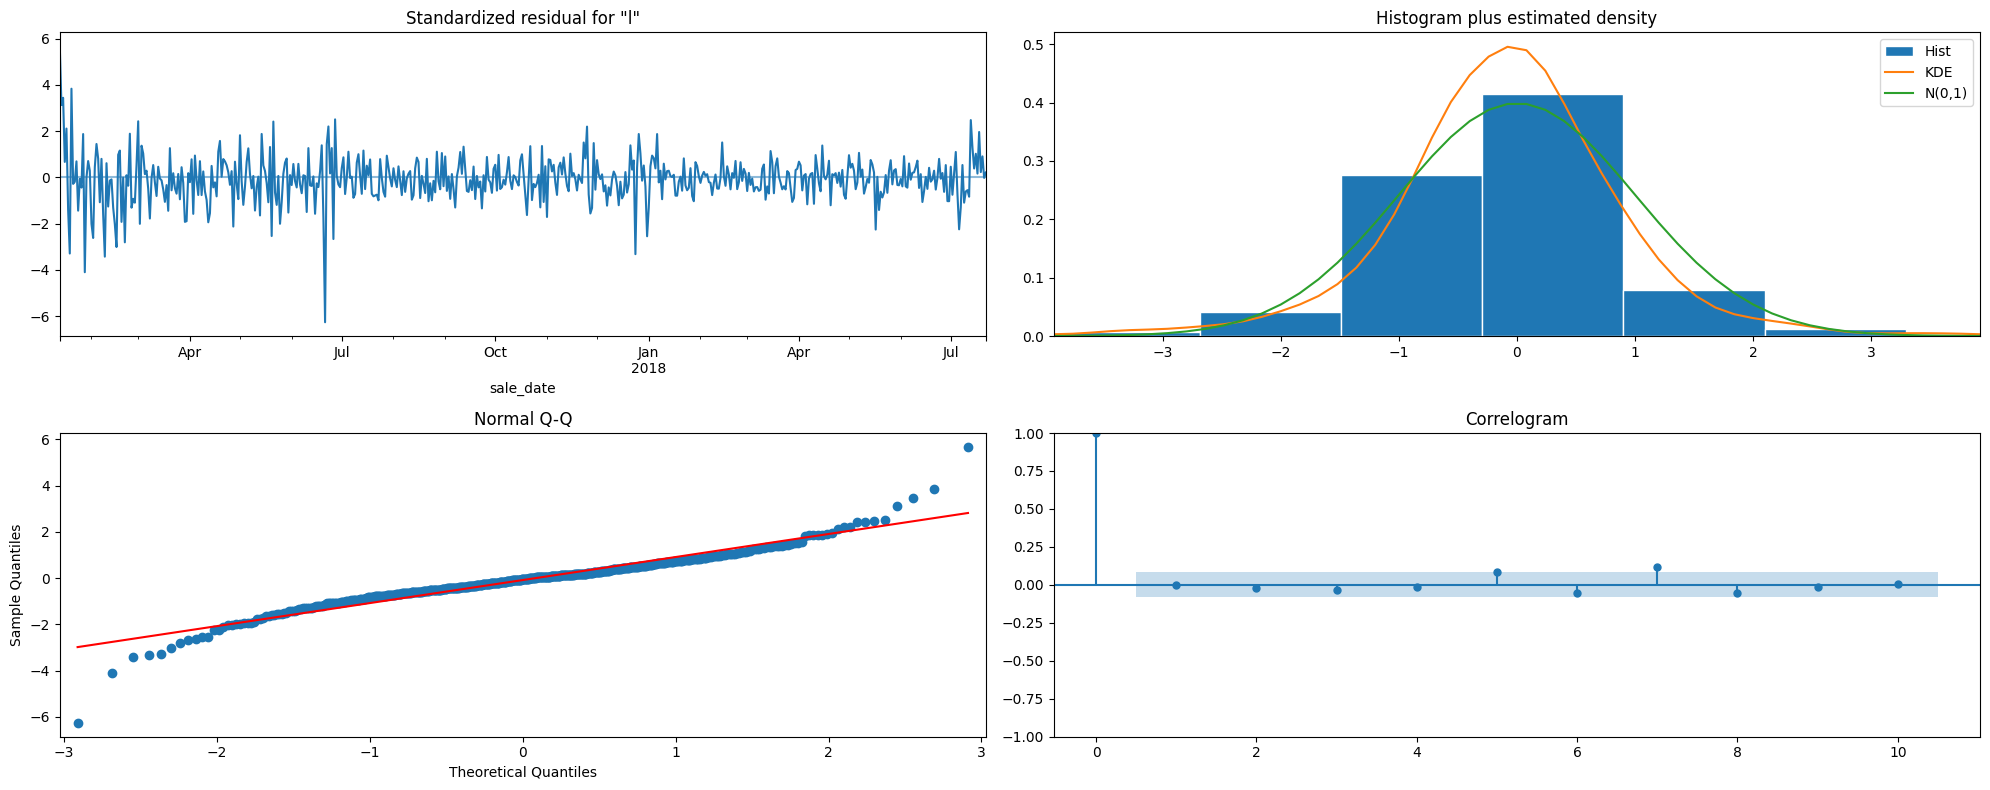

In [18]:
# Ajustando o SARIMAX com todo o histórico para avaliar os resíduos
modelo_sarimax = SARIMAX(df_hist['log_units'], exog = df_hist[eventos], order = ordem_sarima, seasonal_order = ordem_sazonal).fit(disp = False, maxiter = 200)

# Plotando os diagnósticos dos resíduos
fig = modelo_sarimax.plot_diagnostics(figsize = (20, 8))
plt.tight_layout()

plt.show()

In [19]:
# Avaliando os coeficientes dos eventos (efeito percentual sobre as vendas)
coef_eventos = modelo_sarimax.params[eventos]
pd.DataFrame({'coeficiente' : coef_eventos.round(3), 'p-valor' : modelo_sarimax.pvalues[eventos].round(3), 'efeito nas vendas (%)' : (100 * (np.exp(coef_eventos) - 1)).round(1)})

,coeficiente,p-valor,efeito nas vendas (%)
feriado,-0.213,0.000,-19.1
black_friday,1.547,0.000,369.7
pos_black_friday,0.569,0.000,76.7
fim_de_ano,-0.547,0.000,-42.1
greve_caminhoneiros,-0.480,0.216,-38.1


In [20]:
# Aplicando o teste de Ljung-Box nos resíduos (hipótese nula: resíduos sem autocorrelação)
acorr_ljungbox(modelo_sarimax.resid.iloc[8:], lags = [7, 14, 21])

,lb_stat,lb_pvalue
7,16.379690,0.021865
14,24.936310,0.035201
21,40.240785,0.006951


- Os resíduos padronizados oscilam em torno de zero sem um padrão claro, e sua distribuição é próxima da normal, com caudas um pouco mais pesadas causadas por dias atípicos. O correlograma não mostra autocorrelações relevantes.
- O teste de Ljung-Box rejeita a ausência de autocorrelação (p-valor abaixo de 0,05 nos lags 7, 14 e 21). Porém, as autocorrelações individuais dos resíduos são pequenas (todas abaixo de 0,15), e com cerca de 560 observações o teste detecta até autocorrelações fracas. O modelo é considerado adequado, com espaço para melhorias.
- Os coeficientes dos eventos estão de acordo com a EDA: os feriados reduzem as vendas em cerca de 19% e o fim de ano em 42%, enquanto a Black Friday multiplica as vendas por quase 5 vezes (+370%) e os dias seguintes elevam as vendas em 77%. O coeficiente da greve (-38%) não é estatisticamente significativo (p-valor de 0,22), já que são poucos dias e parte da queda é absorvida pelos termos de médias móveis. Ainda assim, a variável é mantida, já que no backtest ela evitou que a queda da greve fosse projetada para as semanas seguintes.

### Modelo 5 - XGBoost

- O XGBoost utiliza as features criadas na etapa 3: calendário, eventos e vendas passadas com defasagem mínima de 28 dias. Em cada janela do backtest, o modelo é treinado com todas as linhas anteriores ao início da janela e prevê os 28 dias seguintes de uma vez.
- Para a escolha dos hiperparâmetros foi feita uma busca simples, avaliada pelo WMAPE médio do backtest:
  - `max_depth`: profundidade máxima das árvores, que controla a complexidade de cada árvore. Como a base tem poucas linhas (cerca de 500 dias), árvores rasas tendem a evitar o overfitting.
  - `n_estimators`: número de árvores criadas pelo modelo.
  - `learning_rate`: peso de cada nova árvore no resultado final. Foi fixado em 0.05, um valor baixo que torna o aprendizado mais gradual.

In [21]:
# Definindo função que cria a função de previsão para um modelo de machine learning
def criar_previsao_ml(modelo):
    def prever(treino, futuro):
        X_treino = df_ml.loc[:treino.index.max(), features]
        y_treino = df_ml.loc[:treino.index.max(), 'order_units']
        X_futuro = df_ml.loc[futuro.index, features].copy()
        X_futuro['greve_caminhoneiros'] = 0       # Evento não conhecido com antecedência
        modelo.fit(X_treino, y_treino)
        return modelo.predict(X_futuro)
    return prever

In [22]:
# Definindo as combinações de hiperparâmetros
grade = [{'max_depth' : d, 'n_estimators' : n} for d, n in itertools.product([2, 3, 5], [200, 500])]

# Avaliando cada combinação no backtest
busca_xgb = []
for params in grade:
    modelo = xgb.XGBRegressor(learning_rate = 0.05, random_state = 42, **params)
    resultado, _ = backtest(criar_previsao_ml(modelo))
    busca_xgb.append({**params, 'WMAPE (%)' : resultado.loc['Média', 'WMAPE (%)']})

busca_xgb = pd.DataFrame(busca_xgb).sort_values('WMAPE (%)')
busca_xgb

,max_depth,n_estimators,WMAPE (%)
4,5,200,20.63
0,2,200,20.72
5,5,500,20.83
2,3,200,20.97
3,3,500,20.98
1,2,500,21.86


In [23]:
# Definindo os melhores hiperparâmetros
params_xgb = busca_xgb.iloc[0][['max_depth', 'n_estimators']].astype(int).to_dict()

# Executando o backtest com os melhores hiperparâmetros
modelo_xgb = xgb.XGBRegressor(learning_rate = 0.05, random_state = 42, **params_xgb)
resultados_modelos['XGBoost'], previsoes_modelos['XGBoost'] = backtest(criar_previsao_ml(modelo_xgb))
resultados_modelos['XGBoost']

,MAE,RMSE,WMAPE (%),Erro total (%)
Janela 1,27.76,36.83,10.72,0.80
Janela 2,69.95,81.74,26.43,-5.14
Janela 3,42.09,59.57,18.98,7.87
Janela 4,54.87,66.32,26.39,17.73
Média,48.67,61.11,20.63,5.31


- A melhor combinação foi `max_depth` = 5 e `n_estimators` = 200, com WMAPE médio de 20,6%. A diferença entre as combinações foi pequena (de 20,6% a 21,9%), o que indica que o modelo não é muito sensível a esses hiperparâmetros.
- O XGBoost ficou em segundo lugar até aqui, com 15% de melhoria em relação ao baseline. Na janela 3 o erro foi de 19,1%: como as features de vendas passadas usam defasagem mínima de 28 dias e a variável de greve está presente, a queda da greve afeta menos a previsão.

### Modelo 6 - LightGBM

- O LightGBM também é um modelo de gradient boosting, mas constrói as árvores de forma diferente do XGBoost: enquanto o XGBoost cresce cada árvore nível a nível, o LightGBM cresce a árvore pela folha que mais reduz o erro. Isso o torna mais rápido e, em muitos casos, mais preciso. O LightGBM é amplamente utilizado em previsão de vendas, tendo sido a base das soluções vencedoras da competição M5, de previsão de vendas do Walmart.
- Foram utilizadas as mesmas features e a mesma busca de hiperparâmetros do XGBoost, para uma comparação justa entre os dois modelos.

In [24]:
# Avaliando cada combinação no backtest
busca_lgb = []
for params in grade:
    modelo = lgb.LGBMRegressor(learning_rate = 0.05, random_state = 42, verbose = -1, **params)
    resultado, _ = backtest(criar_previsao_ml(modelo))
    busca_lgb.append({**params, 'WMAPE (%)' : resultado.loc['Média', 'WMAPE (%)']})

busca_lgb = pd.DataFrame(busca_lgb).sort_values('WMAPE (%)')
busca_lgb

,max_depth,n_estimators,WMAPE (%)
0,2,200,22.66
4,5,200,22.94
1,2,500,24.03
5,5,500,24.15
2,3,200,24.29
3,3,500,24.79


In [25]:
# Definindo os melhores hiperparâmetros
params_lgb = busca_lgb.iloc[0][['max_depth', 'n_estimators']].astype(int).to_dict()

# Executando o backtest com os melhores hiperparâmetros
modelo_lgb = lgb.LGBMRegressor(learning_rate = 0.05, random_state = 42, verbose = -1, **params_lgb)
resultados_modelos['LightGBM'], previsoes_modelos['LightGBM'] = backtest(criar_previsao_ml(modelo_lgb))
resultados_modelos['LightGBM']

,MAE,RMSE,WMAPE (%),Erro total (%)
Janela 1,31.22,39.40,12.06,2.74
Janela 2,67.98,82.13,25.69,1.05
Janela 3,53.32,65.79,24.05,5.34
Janela 4,59.99,73.35,28.86,23.95
Média,53.13,65.17,22.66,8.27


- A melhor combinação foi `max_depth` = 2 e `n_estimators` = 200, com WMAPE médio de 22,7%, também melhor que o baseline, mas atrás do XGBoost, principalmente na janela 4 (28,9%).

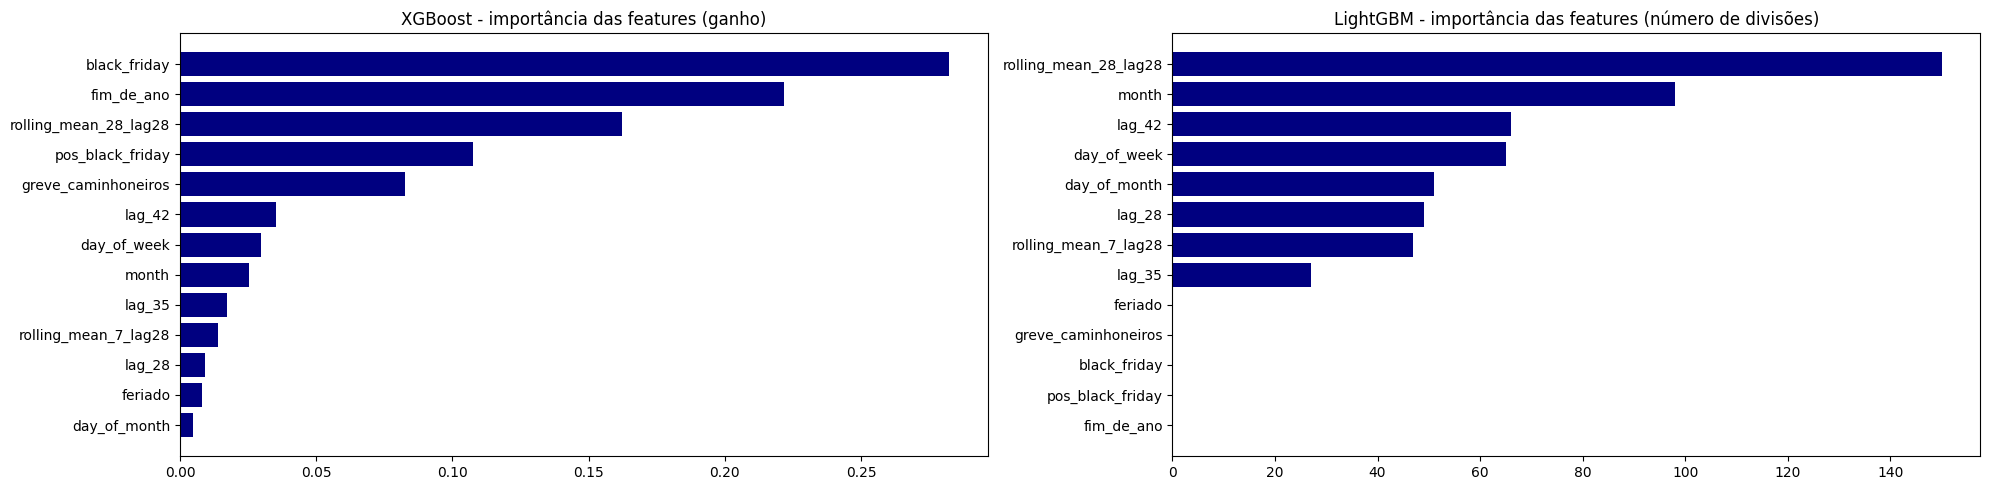

In [26]:
# Treinando os dois modelos com todo o histórico para avaliar a importância das features
modelo_xgb.fit(df_ml.loc[df_ml['split'] != 'teste', features], df_ml.loc[df_ml['split'] != 'teste', 'order_units'])
modelo_lgb.fit(df_ml.loc[df_ml['split'] != 'teste', features], df_ml.loc[df_ml['split'] != 'teste', 'order_units'])

# Plotando a importância das features
fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (20, 5), tight_layout = True)

imp_xgb = pd.Series(modelo_xgb.feature_importances_, index = features).sort_values()
imp_lgb = pd.Series(modelo_lgb.feature_importances_, index = features).sort_values()
axs[0].barh(imp_xgb.index, imp_xgb.values, color = 'navy')
axs[0].set_title('XGBoost - importância das features (ganho)')
axs[1].barh(imp_lgb.index, imp_lgb.values, color = 'navy')
axs[1].set_title('LightGBM - importância das features (número de divisões)')

plt.show()

- No XGBoost, a importância por ganho mede o quanto cada feature reduziu o erro. As variáveis de eventos aparecem no topo porque a Black Friday e o fim de ano concentram os maiores erros da base; em seguida aparece a `rolling_mean_28_lag28`, que representa o nível recente de vendas.
- No LightGBM, a importância mede quantas vezes cada feature foi usada para dividir as árvores. As variáveis de eventos nunca foram utilizadas: por padrão, o LightGBM exige pelo menos 20 registros em cada folha da árvore (`min_child_samples` = 20), e nenhum evento tem mais de 12 dias na base. Sem os eventos, a Black Friday e o fim de ano distorcem o aprendizado do modelo, o que ajuda a explicar o desempenho inferior ao do XGBoost.
- O LightGBM também usou bastante a feature `month`. Como cada mês aparece no máximo duas vezes no histórico, essa feature tende a capturar particularidades de cada ano e não um padrão real, o que é um risco para a generalização do modelo.

### Comparação dos modelos

In [27]:
# Criando a tabela com a média das métricas de cada modelo
comparacao = pd.DataFrame({modelo : resultado.loc['Média'] for modelo, resultado in resultados_modelos.items()}).T
comparacao = comparacao.sort_values('WMAPE (%)')

# Calculando a melhoria em relação ao baseline
comparacao['Melhoria vs baseline (%)'] = (100 * (1 - comparacao['WMAPE (%)'] / comparacao.loc['Seasonal Naive', 'WMAPE (%)'])).round(1)
comparacao

,MAE,RMSE,WMAPE (%),Erro total (%),Melhoria vs baseline (%)
SARIMAX,44.07,55.52,18.63,6.38,22.9
XGBoost,48.67,61.11,20.63,5.31,14.6
LightGBM,53.13,65.17,22.66,8.27,6.2
Seasonal Naive,56.79,68.49,24.15,-6.72,0.0
SARIMA,58.80,68.89,25.24,-6.36,-4.5
ARIMA,74.38,86.89,31.52,-17.39,-30.5


In [28]:
# Avaliando o WMAPE de cada modelo em cada janela
wmape_janelas = pd.DataFrame({modelo : resultado['WMAPE (%)'] for modelo, resultado in resultados_modelos.items()}).T
wmape_janelas.loc[comparacao.index]

,Janela 1,Janela 2,Janela 3,Janela 4,Média
SARIMAX,8.10,27.27,13.06,26.07,18.63
XGBoost,10.72,26.43,18.98,26.39,20.63
LightGBM,12.06,25.69,24.05,28.86,22.66
Seasonal Naive,16.03,23.70,33.64,23.24,24.15
SARIMA,9.92,26.34,38.48,26.20,25.24
ARIMA,22.95,29.94,48.32,24.89,31.52


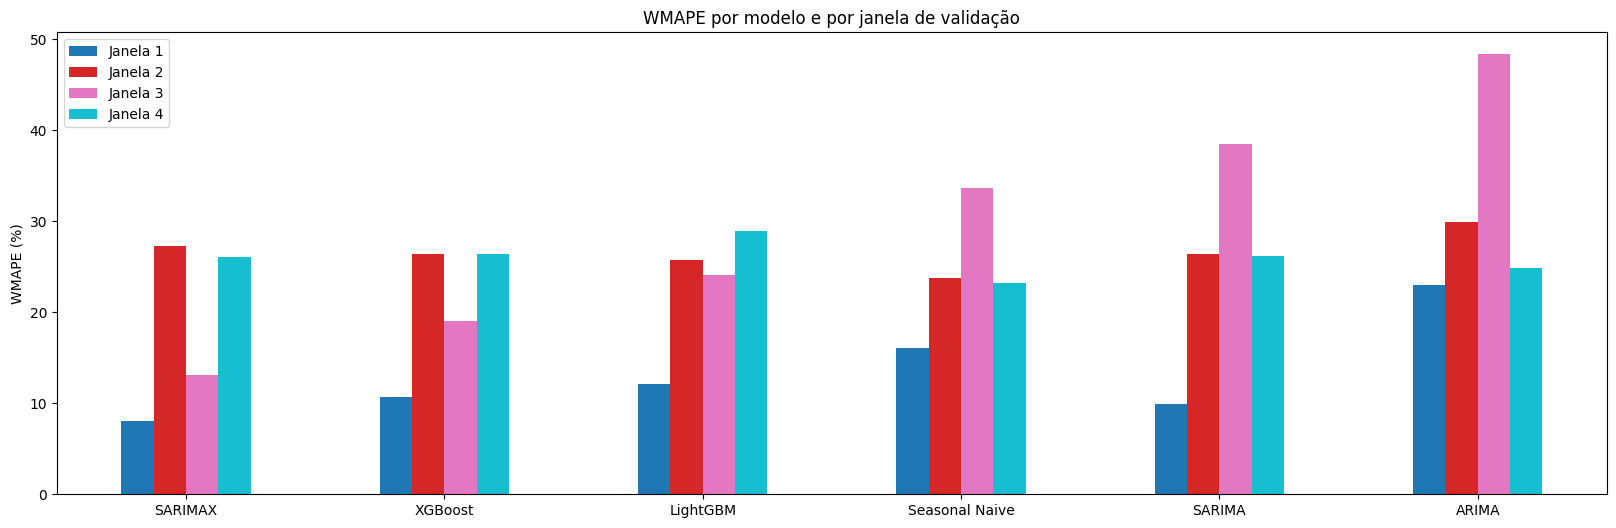

In [29]:
# Plotando o WMAPE de cada modelo por janela
fig, ax = plt.subplots(figsize = (20,6))

wmape_janelas.loc[comparacao.index, ['Janela 1', 'Janela 2', 'Janela 3', 'Janela 4']].plot(kind = 'bar', ax = ax, colormap = 'tab10', rot = 0)
ax.set_ylabel('WMAPE (%)')
plt.title('WMAPE por modelo e por janela de validação')

plt.show()

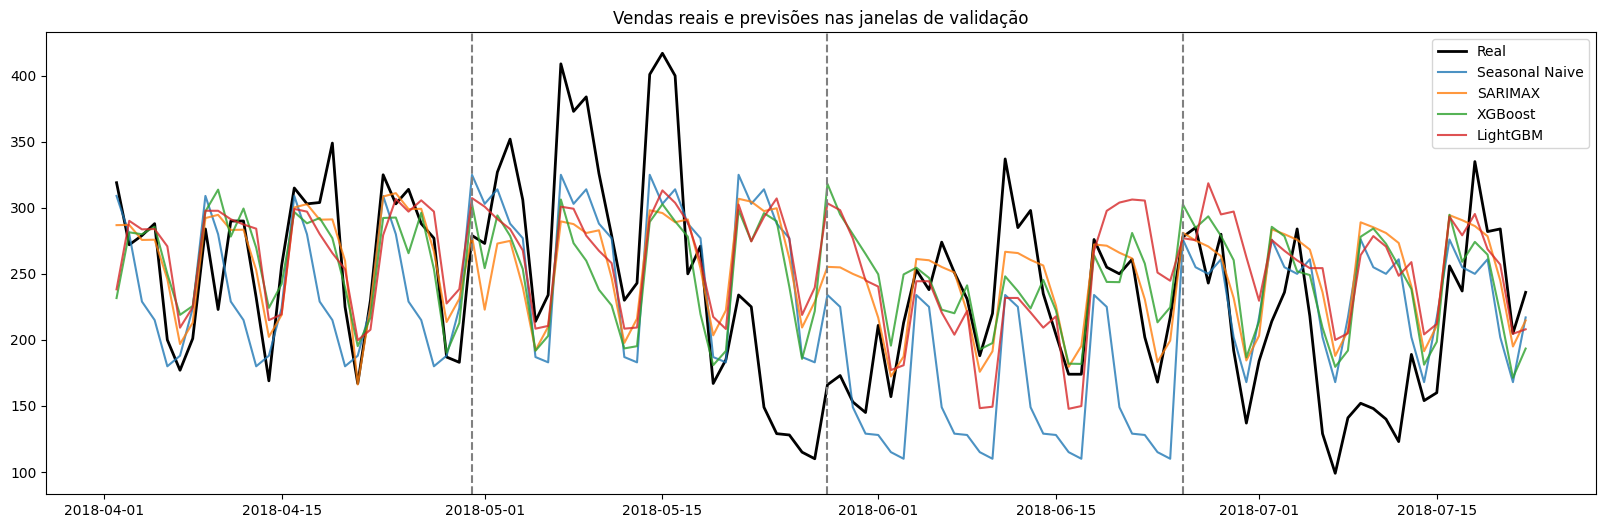

In [30]:
# Plotando as previsões dos modelos nas 4 janelas
modelos_grafico = ['Seasonal Naive', 'SARIMAX', 'XGBoost', 'LightGBM']

fig, ax = plt.subplots(figsize = (20,6))

ax.plot(df_hist.loc[inicio_janelas[0]:, 'order_units'], label = 'Real', color = 'black', linewidth = 2)
for modelo in modelos_grafico:
    ax.plot(previsoes_modelos[modelo], label = modelo, alpha = 0.8)
for inicio in inicio_janelas[1:]:
    ax.axvline(inicio, color = 'gray', linestyle = '--')
plt.title('Vendas reais e previsões nas janelas de validação')
plt.legend()

plt.show()

- O **SARIMAX** foi o melhor modelo na validação, com WMAPE médio de 18,6% (23% de melhoria em relação ao baseline), seguido pelo XGBoost (20,6%) e pelo LightGBM (22,7%). O ARIMA e o SARIMA sem eventos não superaram o Seasonal Naive.
- O SARIMAX foi o melhor modelo nas janelas 1 e 3. Nas janelas 2 e 4 ele ficou próximo dos demais modelos, mas atrás do Seasonal Naive. Essas duas janelas foram difíceis para todos os modelos (WMAPE entre 23% e 30%), por conterem eventos não representados nos dados: o pico de vendas de meados de maio, a greve e as semanas finais da Copa do Mundo.
- O erro no total do período deve ser lido com cuidado, já que a média das 4 janelas compensa erros positivos e negativos. Na janela 4, por exemplo, SARIMAX, XGBoost e LightGBM superestimaram o total das 4 semanas entre 16% e 24%, por causa da queda de vendas durante a Copa.
- No gráfico, é possível ver que o SARIMAX e o XGBoost reproduzem bem o padrão semanal e o nível de vendas, mas nenhum modelo antecipa o pico de maio nem a queda de julho.

### Salvando as configurações dos modelos

- Na etapa 5, todos os modelos são treinados novamente com todo o histórico (treino + validação) e fazem a previsão das 4 semanas de teste, que até agora não foram utilizadas. Para isso, as configurações escolhidas nesta etapa são salvas em um arquivo.

In [31]:
# Salvando as configurações escolhidas
configuracoes = {
    'horizonte' : horizonte,
    'eventos' : eventos,
    'features_ml' : features,
    'arima' : {'order' : list(ordem_arima)},
    'sarima' : {'order' : list(ordem_sarima), 'seasonal_order' : list(ordem_sazonal)},
    'xgboost' : {'learning_rate' : 0.05, 'random_state' : 42, **params_xgb},
    'lightgbm' : {'learning_rate' : 0.05, 'random_state' : 42, **params_lgb}
}

with open(r'../models/model_configs.json', 'w') as arquivo:
    json.dump(configuracoes, arquivo, indent = 4)

configuracoes

{'horizonte': 28,
 'eventos': ['feriado',
  'black_friday',
  'pos_black_friday',
  'fim_de_ano',
  'greve_caminhoneiros'],
 'features_ml': ['month',
  'day_of_week',
  'day_of_month',
  'lag_28',
  'lag_35',
  'lag_42',
  'rolling_mean_7_lag28',
  'rolling_mean_28_lag28',
  'feriado',
  'black_friday',
  'pos_black_friday',
  'fim_de_ano',
  'greve_caminhoneiros'],
 'arima': {'order': [2, 1, 2]},
 'sarima': {'order': [1, 1, 1], 'seasonal_order': [0, 1, 1, 7]},
 'xgboost': {'learning_rate': 0.05,
  'random_state': 42,
  'max_depth': 5,
  'n_estimators': 200},
 'lightgbm': {'learning_rate': 0.05,
  'random_state': 42,
  'max_depth': 2,
  'n_estimators': 200}}

### Conclusões da etapa de modelagem

- **Validação**: o backtest com 4 janelas de 28 dias se mostrou essencial. Avaliando somente a última janela (validação da etapa 3), o Seasonal Naive teria o menor erro entre os modelos e a conclusão seria diferente.
- **Modelos estatísticos**: a sazonalidade semanal (SARIMA) e principalmente as variáveis de eventos (SARIMAX) foram as decisões com maior impacto no resultado. A transformação logarítmica trouxe um ganho pequeno e foi mantida.
- **Modelos de machine learning**: o XGBoost superou o LightGBM, que não conseguiu utilizar as variáveis de eventos com a configuração padrão. Os dois modelos ficaram atrás do SARIMAX, o que é esperado com uma base de cerca de 500 dias: modelos estatísticos com poucos parâmetros tendem a funcionar melhor que modelos de machine learning em séries curtas.
- **Melhor modelo na validação**: SARIMAX(1,1,1)(0,1,1)7 com variáveis de eventos, com WMAPE médio de 18,6%.
- **Limitações**: eventos que não estão nos dados (promoções, Copa do Mundo) explicam boa parte dos maiores erros, e o histórico de 19 meses não permite modelar a sazonalidade anual.
- **Próxima etapa**: todos os modelos serão treinados novamente com o histórico completo (treino + validação) e avaliados na base de teste, que ainda não foi utilizada, para a escolha final do modelo.